# ДЗ 2. Масштабирование, поворот и ключевые точки

Уменьшение и обрезка изображения, поворот, поиск ключевых точек ORB и их сопоставление между исходным и повёрнутым изображением (OpenCV).

In [47]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
import pandas as pd
import matplotlib.pyplot as plt

In [48]:
# Load the image
image = cv.imread('sea.JPG')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Apply Canny edge detection with fixed thresholds (50 and 150)
edges = cv.Canny(image, 50, 150)

# Calculate the mean intensity of the image
mean_intensity = np.mean(image)

# Calculate lower and upper thresholds based on the mean intensity
lower_threshold = mean_intensity * 2 / 3
upper_threshold = mean_intensity * 4 / 3

# Apply Canny edge detection with adaptive thresholds
edges_filtered = cv.Canny(image, lower_threshold, upper_threshold)
cv.imwrite('output_image.jpg', edges_filtered)

True

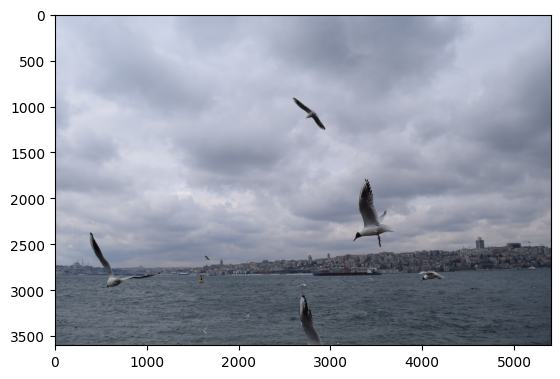

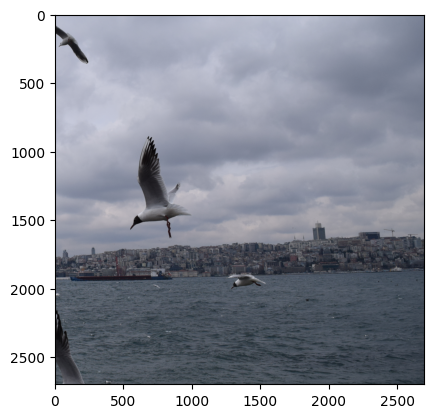

(<matplotlib.image.AxesImage at 0x7fe860972260>, None)

In [49]:
# Decrease the size of the image by 10%
width = int(image.shape[1] * 0.9)
height = int(image.shape[0] * 0.9)
dim = (width, height)
resized = cv.resize(image, dim, interpolation = cv.INTER_AREA)
plt.imshow(resized),plt.show()

# Crop the image from the bottom (take only the part with y >= 900)
# and from the right (take only the part with x >= 2700)
cropped = resized[900:, 2700:]
plt.imshow(cropped),plt.show()

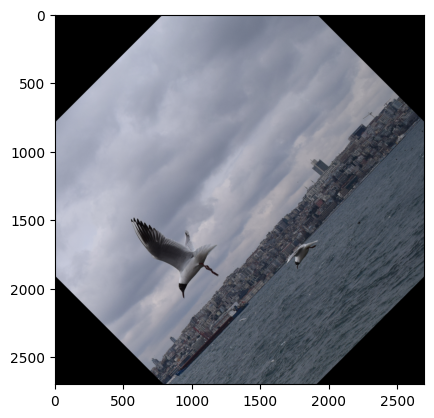

(<matplotlib.image.AxesImage at 0x7fe86091c220>, None)

In [50]:
# Determine the dimensions of the cropped image
(h_cropped, w_cropped, d) = cropped.shape

# Determine the center of the cropped image
center = (w_cropped // 2, h_cropped // 2)

# Rotate the cropped image by 45 degrees around the center
M = cv.getRotationMatrix2D(center, 45, 1.0)

# Matrix multiplication followed by a vector addition
rotated = cv.warpAffine(cropped, M, (w_cropped, h_cropped))
plt.imshow(rotated),plt.show()

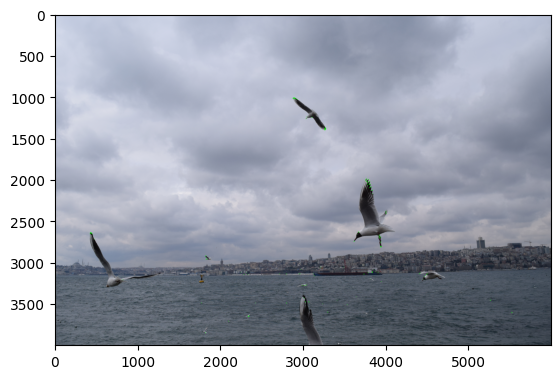

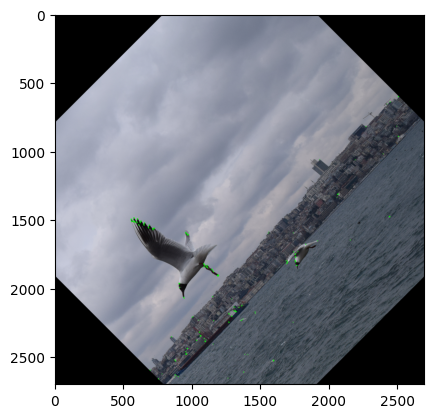

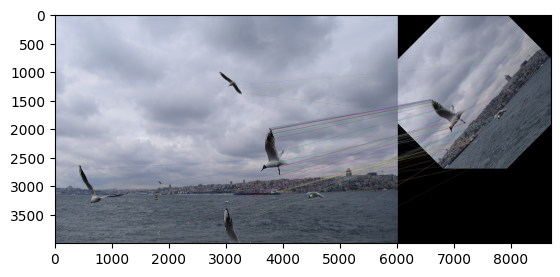

(<matplotlib.image.AxesImage at 0x7fe88fb24f70>, None)

In [51]:
# Create an ORB object
orb = cv.ORB_create()

# Detect keypoints on the original image
seaguls = orb.detect(image,None)

# Detect keypoints on the rotated image
seaguls_2 = orb.detect(rotated,None)

# Compute descriptors for the detected keypoints on 
# the original image
seaguls, des = orb.compute(image, seaguls)

# Compute descriptors for 
#the detected keypoints on the rotated image
seaguls_2, des_2 = orb.compute(rotated, seaguls_2)

# Draw keypoints on the original image
img2 = cv.drawKeypoints(image, seaguls, None, color=(0,255,0))

# Draw keypoints on the rotated image
img2_2 = cv.drawKeypoints(rotated, seaguls_2, None, color=(0,255,0))
plt.imshow(img2), plt.show()
plt.imshow(img2_2), plt.show()

# Create a BFMatcher object using the Hamming distance
bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)

# Match the descriptors
matches = bf.match(des,des_2)
img3 = cv.drawMatches(image,seaguls,rotated,seaguls_2,matches, None)
plt.imshow(img3),plt.show()